# **MODULE 7 — TIME-DOMAIN SIGNAL ANALYSIS 🎧**

Now we're moving from understanding digital audio parameters to actually analysing audio signals using Python.

In the previous module, we learned that digital audio is represented as a sequence of numerical samples. In this module, we'll study how those samples behave over time and how to extract useful information from them.

Imagine recording someone saying:

> "Hello, how are you?"

The recording contains:

- Moments of silence before speaking.
- Different amplitude levels while speaking.
- Strong and weak sounds.
- Periodic vocal-fold vibrations.
- Unvoiced sounds and noise-like components.
- Pauses between words.

Time-domain analysis helps us examine these characteristics directly from the waveform.

**Our objective:** Learn to read an audio waveform, calculate basic signal measurements, identify silence and clipping, and compare speech recordings.

# **7.1 What is the Time Domain?**

The **time domain** is a way of representing a signal by showing how its amplitude changes over time.

In audio processing, we plot:

- X-axis → Time (seconds).
- Y-axis → Amplitude (signal value).

For example, when someone speaks into a microphone, the amplitude of the recorded signal changes continuously across the recording's sample positions.

[11.3. Bandwidth extension (BWE) — Introduction to Speech Processing](https://images.openai.com/static-rsc-4/DOI_k70pPkIrU1rUChUrYIUDfA1SpKpl0jAe3ROc0lmx4W7XgjlwcTds7ui-RITIRku75CmxaieqUrMXqwip6uz5gnM_LXL6_4friKgjKbgy9cJdMd2q_UmOWHhKzVFnz9pbPMGcyZULn3vtu7qvu-TZVOwopA0zp6t7QKatSU4?purpose=inline)

[speechprocessingbook.aalto.fi](https://speechprocessingbook.aalto.fi/Enhancement/Bandwidth_extension_BWE.html?utm_source=chatgpt.com)

### **Mathematical representation**

A continuous-time signal is represented as:

\\[ x(t) \\]

A digital audio signal is represented as:

\\[ \boxed{x[n]} \\]

Where:

- \\(x[n]\\) = amplitude of the nth audio sample.
- \\(n\\) = sample index.
- \\(t\\) = time.

The time corresponding to sample index \\(n\\) is:

\\[ \boxed{t_n=\frac{n}{f_s}} \\]

Where \\(f_s\\) is the sampling rate.

### **Example**

Suppose an audio recording has a sampling rate of 16,000 Hz.

The time corresponding to sample index 8,000 is:

\\[ t=\frac{8000}{16000} \\]

\\[ \boxed{t=0.5\text{ seconds}} \\]

Therefore, sample 8,000 represents the audio signal at approximately 0.5 seconds.

# **7.2 Amplitude vs Time**

An audio waveform shows how the signal amplitude changes over time.

[Microsoft's New AI Tool Just Needs to Hear Three Seconds of Your Voice to Mimic You](https://images.openai.com/static-rsc-4/i-Cu-oexODoLBC5SKcQmJ-QV_fh_tcNdqI53Eanl0aA-KzataGax5ms-kDkK6U6r1x11BY15j36HcGzO2dtxGDeUC49OvUcV_CeXb4MsXfjBt0MIyy8RF40ZRnaEfMBHdLNaad0g76Fc_zelSRzJvvDe0GqiO1KpFp2kmbtCBWU?purpose=inline)

[gizmodo.com](https://gizmodo.com/microsoft-ai-voice-mimic-deepfake-natural-copy-audio-1849969596?utm_source=chatgpt.com)

### **Understanding the axes**

**X-axis — Time**

Shows when each sample occurs in the recording.

**Y-axis — Amplitude**

Shows the numerical value of each sample.

For normalized floating-point audio, amplitude is commonly represented approximately between:

\\[ -1 \leq x[n] \leq 1 \\]

Here:

- Positive values represent positive signal excursions.
- Negative values represent negative signal excursions.
- Zero represents the signal's reference level.

The exact amplitude range depends on the audio representation.

### **Important observation**

A waveform does not directly show the words being spoken.

It shows the signal's amplitude over time.

To investigate its frequency content, we'll later study frequency-domain analysis and spectrograms.

# **7.3 What are Audio Samples?**

An audio sample is one numerical measurement of the signal amplitude at a particular sampling instant.

Consider this example:

```
audio = [0.10, 0.25, 0.48, 0.32, 0.05, -0.20, -0.40]
```

Each value represents one sample.

| Sample index | Amplitude |
| ------------ | --------- |
| 0            | 0.10      |
| 1            | 0.25      |
| 2            | 0.48      |
| 3            | 0.32      |
| 4            | 0.05      |
| 5            | -0.20     |
| 6            | -0.40     |

If the sampling rate is 16 kHz, the sample interval is:

\\[ T_s=\frac{1}{16000} \\]

\\[ T_s=62.5\ \mu s \\]

The samples are separated by 62.5 microseconds.

## **7.4 Sample Indexing**

Digital audio uses integer sample indices:

\\[ n=0,1,2,3,\ldots,N-1 \\]

To convert a sample index into time:

\\[ \boxed{t=\frac{n}{f_s}} \\]

To convert time into an approximate sample index:

\\[ \boxed{n=\lfloor t f_s\rfloor} \\]

### **Example**

Suppose:

- Sampling rate = 16,000 Hz.
- Required time = 2 seconds.

\\[ n=2\times16000 \\]

\\[ \boxed{n=32000} \\]

So sample index 32,000 corresponds to 2 seconds.

**Practical importance:** Sample indexing allows us to select particular portions of an audio recording.

For example, to extract audio between 2 and 4 seconds:

```
start = int(2 * sample_rate)end = int(4 * sample_rate)segment = audio[start:end]
```

# **7.5 Signal Duration**

Signal duration is the total time represented by an audio recording.

\\[ \boxed{T=\frac{N}{f_s}} \\]

Where:

- \\(T\\) = duration in seconds.
- \\(N\\) = samples per channel.
- \\(f_s\\) = sampling rate.

### **Example**

Suppose:

- Number of samples = 160,000.
- Sampling rate = 16,000 Hz.

\\[ T=\frac{160000}{16000} \\]

\\[ \boxed{T=10\text{ seconds}} \\]

For stereo audio, calculate using the number of samples in each channel, not the combined number of channel values.

# **7.6 Peak Amplitude**

**Peak amplitude is the maximum absolute sample value in an audio signal.**

It measures the largest instantaneous amplitude excursion from zero.

Mathematically:

\\[ \boxed{A\_{\text{peak}}=\max_n |x[n]|} \\]

### **Example**

Consider:

\\[ x=[0.1,-0.4,0.8,-0.9,0.3] \\]

Absolute values:

\\[ |x|=[0.1,0.4,0.8,0.9,0.3] \\]

Therefore:

\\[ \boxed{A\_{\text{peak}}=0.9} \\]

### **Why is peak amplitude important?**

It helps us:

- Identify very loud signal peaks.
- Detect possible clipping.
- Compare signal levels.
- Monitor recording levels.
- Understand how close the signal is to its digital maximum.

[Amplitude, quantified · Factual Audio](https://images.openai.com/static-rsc-4/u6iAMCSb6C0F9K3w2f-iZTbOrASrExer6lqFwYGOn68fK0n2lZhX9n4-MsJ1wIUecPPySxLDXQmNWwgkXJ56NAVfQx3dRaGtLVpirGpIss4XLduZooW2cV7wqU0j7cmre7Lm4SuG6F_MrL6V5-EAP03wYTKLuM-MxCTH5EYMWxU?purpose=inline)

[factualaudio.com](https://factualaudio.com/post/amplitude/?utm_source=chatgpt.com)

# **7.7 Mean Amplitude**

Mean amplitude is the arithmetic average of all sample values.

\\[ \boxed{\mu=\frac{1}{N}\sum\_{n=0}^{N-1}x[n]} \\]

Where:

- \\(\mu\\) = mean amplitude.
- \\(N\\) = total number of samples.
- \\(x[n]\\) = individual sample.

### **Example**

Suppose:

\\[ x=[0.2,0.4,-0.2,-0.4] \\]

Then:

\\[ \mu=\frac{0.2+0.4-0.2-0.4}{4} \\]

\\[ \boxed{\mu=0} \\]

Notice something interesting: the signal contains non-zero amplitudes, but its mean is zero.

This happens because positive and negative values cancel each other.

**Important:** Mean amplitude alone is not a reliable measurement of how loud an audio signal is.

# **7.8 Absolute Amplitude**

Absolute amplitude means taking the magnitude of each sample without considering its sign.

\\[ \boxed{x\_{\text{abs}}[n]=|x[n]|} \\]

For example:

Original signal:

\\[ x=[0.2,-0.5,0.8,-0.3] \\]

Absolute amplitude:

\\[ |x|=[0.2,0.5,0.8,0.3] \\]

[File:Full-wave Rectified Sine Wave.svg - Wikimedia Commons](https://images.openai.com/static-rsc-4/jtu-zg2kMGF-_bIybWKkzP3Zc0TWuNie5mYtM2_DNPardGYY9fTvqYzKNCHrDSAuyiQJwPDzy6qxQc66vuoEM_e-wjcHvgad7uhcHGUFaStPJxtx-y8P2tahigo9wVjOM6fdpLTvS5bIkN-RTWETTaCRlJLMHedelNngjyqXcb8?purpose=inline)

[commons.wikimedia.org](https://commons.wikimedia.org/wiki/File%3AFull-wave_Rectified_Sine_Wave.svg?utm_source=chatgpt.com)

### **Why is it useful?**

Absolute amplitude is useful for:

- Measuring signal magnitude.
- Detecting speech activity.
- Calculating mean absolute amplitude.
- Building simple energy-based voice activity detectors.

## **7.9 Mean Absolute Amplitude**

Mean absolute amplitude calculates the average magnitude of all samples.

\\[ \boxed{MAA=\frac{1}{N}\sum\_{n=0}^{N-1}|x[n]|} \\]

Using our earlier signal:

\\[ x=[0.2,0.4,-0.2,-0.4] \\]

\\[ MAA=\frac{0.2+0.4+0.2+0.4}{4} \\]

\\[ \boxed{MAA=0.3} \\]

Unlike signed mean amplitude, mean absolute amplitude does not cancel positive and negative samples.

# **7.10 RMS — Root Mean Square**

Very important audio feature

**RMS (Root Mean Square) measures the effective magnitude of a signal.**

It is commonly used to analyse the overall signal level of audio.

The formula is:

\\[ \boxed{ RMS=\sqrt{\frac{1}{N}\sum\_{n=0}^{N-1}x[n]^2} } \\]

There are three operations:

1. Square every sample.
2. Calculate the average of the squared values.
3. Take the square root.

### **Example**

Suppose:

\\[ x=[0.2,-0.4,0.6,-0.8] \\]

**Step 1 — Square the samples**

\\[ x^2=[0.04,0.16,0.36,0.64] \\]

**Step 2 — Calculate the mean**

\\[ \frac{0.04+0.16+0.36+0.64}{4} =0.3 \\]

**Step 3 — Take the square root**

\\[ RMS=\sqrt{0.3} \\]

\\[ \boxed{RMS\approx0.548} \\]

### **Why is RMS important?**

RMS is useful for:

- Measuring average signal level.
- Comparing recording levels.
- Analysing speech intensity.
- Detecting quieter and louder regions.
- Audio normalization and signal monitoring.

[Metering: Peak, RMS and LUFS | SpringerLink](https://images.openai.com/static-rsc-4/wHBJW5BbePBIWfAPRSoTpGUIi2mKCfmlGWOCC0fq90KFp4VgzV9WHw2O2cZZNOCGIjs9SYKbGx4opFPEB8ZRuZSQD67Fueh2Ak4gwY6EaBWwZXTTVkn0MFX8PuXg_vxzoI8n0uGaHV2P-h96HpjcO86oawJXQOaZwVvbOJ3z658?purpose=inline)

[link.springer.com](https://link.springer.com/chapter/10.1007/978-3-031-40067-4_26?utm_source=chatgpt.com)

### **Mean amplitude vs Mean absolute amplitude vs RMS**

| Measurement             | Formula                             | What it measures           |
| ----------------------- | ----------------------------------- | -------------------------- |
| Mean amplitude          | \\(\frac{1}{N}\sum x[n]\\)          | Average signed value       |
| Mean absolute amplitude | \\(\frac{1}{N}\sum \|x[n]\|\\)      | Average magnitude          |
| RMS                     | \\(\sqrt{\frac{1}{N}\sum x[n]^2}\\) | Effective signal magnitude |
| Peak amplitude          | \\(\max \|x[n]\|\\)                 | Largest magnitude          |

**Important:** RMS is not exactly the same as perceived loudness. Human loudness perception also depends on frequency, duration, and listening conditions.

# **7.11 Signal Energy**

Signal energy measures the accumulated squared amplitude of a discrete signal.

For a finite discrete-time audio signal:

\\[ \boxed{E=\sum\_{n=0}^{N-1}|x[n]|^2} \\]

Where:

- \\(E\\) = discrete signal energy measure.
- \\(x[n]\\) = sample amplitude.
- \\(N\\) = number of samples.

### **Example**

Suppose:

\\[ x=[0.2,-0.4,0.6] \\]

Then:

\\[ E=0.2^2+(-0.4)^2+0.6^2 \\]

\\[ E=0.04+0.16+0.36 \\]

\\[ \boxed{E=0.56} \\]

### **Relationship between RMS and signal energy**

We know:

\\[ RMS=\sqrt{\frac{E}{N}} \\]

Therefore:

\\[ \boxed{E=N\times RMS^2} \\]

This relationship is useful when calculating signal features.

### **Energy vs RMS**

| Signal energy                           | RMS                                 |
| --------------------------------------- | ----------------------------------- |
| Sum of squared samples                  | Square root of mean squared samples |
| Depends on recording length             | Normalized by sample count          |
| Useful for accumulated signal magnitude | Useful for average signal level     |

**Important distinction:** This discrete energy measure is not automatically physical acoustic energy measured in joules. That would require calibration and knowledge of the recording system.

# **7.12 Zero Crossing Rate (ZCR)**

Important speech feature

**Zero Crossing Rate measures how frequently an audio signal changes sign between consecutive samples.**

In simple terms, it counts how often the waveform crosses the zero-amplitude reference.

[Audio Features — The GenAI Guidebook](https://images.openai.com/static-rsc-4/fFlmfS5Ez0vgeRRN3AtJrwrTvW8n-1laI3XwORXxOP25UdT-iYluZHQxHxY_ZVUucLAx9R6vppM44T9DfeuP0Bh19xVxSnW5wnq9_btn0LzrenCT_4COonxB-wS8-YmA1kkVVGqxttR0d9dPzFJFYFiIWcESm9r_OhymUwGdF_0?purpose=inline)

[ravinkumar.com](https://ravinkumar.com/GenAiGuidebook/audio/audio_feature_extraction.html?utm_source=chatgpt.com)

### **Why is ZCR useful?**

Different types of speech sounds can have different zero-crossing patterns.

For example:

- Voiced sounds often have relatively lower ZCR.
- Unvoiced fricatives such as /s/ often have relatively higher ZCR.

This is a general tendency, not a universal rule.

### **Mathematical formula**

One common definition for a frame containing \\(N\\) samples is:

\\[ \boxed{ ZCR=\frac{1}{2N} \sum\_{n=1}^{N-1} |\operatorname{sgn}(x[n])-\operatorname{sgn}(x[n-1])| } \\]

Where:

\\[ \operatorname{sgn}(x)= \begin{cases} +1 & x>0\\\ 0 & x=0\\\ -1 & x<0 \end{cases} \\]

The exact normalization and treatment of zero-valued samples can vary between implementations.

### **Example**

Consider two simplified signals:

**Signal A:**

\\[ [1,1,1,-1,-1,-1] \\]

It has one sign change.

**Signal B:**

\\[ [1,-1,1,-1,1,-1] \\]

It has five sign changes.

Signal B has a much higher zero-crossing rate.

### **Why ZCR matters in speech processing**

ZCR can help distinguish:

- Voiced and unvoiced regions.
- Speech and some types of background noise.
- Periodic and noise-like signal segments.

It is often combined with short-time energy or RMS rather than used alone.

# **7.13 Silence and Non-Silent Regions**

A speech recording does not contain speech continuously.

It may include:

- Silence before speech begins.
- Pauses between words.
- Pauses between sentences.
- Breathing sounds.
- Background noise.

[8.1. Voice Activity Detection (VAD) — Introduction to Speech Processing](https://images.openai.com/static-rsc-4/DCciVJ3npsJ5K2VSdfQ_97naeZwfOv-LlMskliO_BH3LCt3T11siYOCA8udOHBvBnztKOfnzUhp_yD4dQC0XBpQ20PXUw59b-dQgwrIzQH2MCrrvJniNAncbqNz65r84Mzt_PAxZDFV1baByvLxZe-dcrRnhRclPnJF7ifw0sO4?purpose=inline)

[speechprocessingbook.aalto.fi](https://speechprocessingbook.aalto.fi/Recognition/Voice_activity_detection.html?utm_source=chatgpt.com)

### **What is silence?**

In a digital recording, ideal silence means:

\\[ x[n]=0 \\]

for every sample in the region.

However, real recordings rarely contain perfect digital silence because of:

- Microphone self-noise.
- Environmental noise.
- Electrical interference.
- Recording equipment noise.

Therefore, practical audio-processing systems often define silence using an amplitude or energy threshold.

### **Silence detection using RMS**

Suppose we calculate RMS over short frames.

If the RMS of a frame falls below a chosen threshold, we can classify that frame as a potential silent or low-energy region.

For example:

\\[ RMS<0.01 \\]

This could be used as a simple threshold for normalized audio.

However, the correct threshold depends on the recording environment and noise level.

### **Voice Activity Detection (VAD)**

Voice Activity Detection is the process of identifying regions containing speech.

A VAD system attempts to distinguish speech from non-speech segments.

Applications:

- Removing long silent regions.
- Meeting transcription.
- Speech-recognition preprocessing.
- Voice communication.
- Speech dataset segmentation.

**Important:** Silence detection and VAD are not identical. A simple threshold detector can miss quiet speech or mistake background noise for speech. Modern VAD systems use more sophisticated features and models.

# **7.14 Periodic and Aperiodic Signals**

Audio signals can exhibit different patterns depending on how they are generated.

## **A. Periodic Signals**

A periodic signal repeats its waveform pattern after a fixed time interval.

Mathematically:

\\[ \boxed{x(t)=x(t+T)} \\]

Where \\(T\\) is the time period.

Examples:

- A sinusoidal tone.
- Approximately periodic voiced speech.
- A tuning fork producing a steady tone.

[Anatomy of an audio signal · Factual Audio](https://images.openai.com/static-rsc-4/aap05tiQUhbWuFsTbZrppiQ0hCJW0NnExu8EDP0E9sEqe6H-hl1WrRENhC97mqJGpmNH4jPshnLriLn6-eGPxIqfztvxUgBlrGEYil4GbbZe76GsavygxgQZabm3bugUIsRCuMrlqyK5udJEzqY6tvlaGwMa2W6g5PpPsiaYQIY?purpose=inline)

[factualaudio.com](https://factualaudio.com/post/anatomy/?utm_source=chatgpt.com)

### **Characteristics**

- Repeating waveform patterns.
- Has a definable period.
- Has a fundamental frequency.
- Contains harmonics when the waveform is non-sinusoidal.

## **B. Aperiodic Signals**

An aperiodic signal does not repeat in a regular pattern over time.

Examples:

- White noise.
- Many environmental sounds.
- Unvoiced fricatives such as /s/ and /f/.

[白色雑音（ホワイトノイズ）](https://images.openai.com/static-rsc-4/KiSN1mkKrxbXyEaDB2Ia4Y8mqKLmtNQ2eihLrJ651_QN_jrtp5Fr2grv6tTsmLpdv6GEH4WSGhnpE0zQEDDxzgyECNEPxuAjBIiPOFg_NMFDGe9TOVKStycoIIuIenS7cq4udkwJhm_DD2sWGvkuFcDuKvu4_ArTZVlu71KjKhM?purpose=inline)

[physics.thick.jp](https://physics.thick.jp/Spectrum_Analysis/Section2/2-7.html?utm_source=chatgpt.com)

### **Periodic vs Aperiodic**

| Periodic                       | Aperiodic                                   |
| ------------------------------ | ------------------------------------------- |
| Repeats after a fixed interval | Does not repeat regularly                   |
| Has a definable period         | No fixed repeating period                   |
| Has a fundamental frequency    | May not have a single fundamental frequency |
| Example: steady voiced tone    | Example: fricative noise                    |

### **Speech contains both!**

This is particularly important.

Consider the sentence:

> "See the sun."

- Vowels generally contain periodic voiced components.
- /s/ sounds contain predominantly aperiodic turbulent noise.
- Some consonants contain both voiced and noise-like components.

Therefore, natural speech is a mixture of different acoustic patterns.

# **7.15 Speech Signal Characteristics**

Human speech is not a simple sine wave.

It is a complex, time-varying signal.

[Beginner’s guide to Speech Analysis | by K V Vijay Girish | TDS Archive | Medium](https://images.openai.com/static-rsc-4/3T05tih2Brp_7ZsLKCW9xqLV9pAZZDVRFyilxkxXCBQpvKitffTuy7IREUGzRjLXEUTGU4BBd9RD2uynebF0jRNSfPr7H92jlcX8TD9mHLwzgH2YA_Xx3FORgSh-26gAOjDovp1Uh4cGruqpkgtBCRVf41Sr5-6K5pT4WsxHNo0?purpose=inline)

[medium.com](https://medium.com/data-science/beginners-guide-to-speech-analysis-4690ca7a7c05?utm_source=chatgpt.com)

Some important characteristics:

| Characteristic       | Description                        |
| -------------------- | ---------------------------------- |
| Non-stationary       | Signal properties change over time |
| Periodic components  | Present in voiced speech           |
| Aperiodic components | Present in unvoiced sounds         |
| Variable amplitude   | Changes with speaking intensity    |
| Pauses               | Occur between words and sentences  |
| Different durations  | Phonemes have different lengths    |
| Background noise     | Can be present during recording    |

### **What does non-stationary mean?**

A signal is non-stationary when its statistical properties change over time.

For example, during a spoken sentence:

- A vowel may have strong periodicity.
- A fricative may contain noise-like energy.
- A pause may have very low amplitude.

The signal characteristics change as the speaker moves from one sound to another.

This is why speech is commonly analysed using short-time frames rather than treating an entire recording as one stationary signal.

We'll study this more deeply when we reach short-time signal analysis and spectrograms.

# **7.16 Clipping and Distortion**

Important for real-world datasets

**Clipping occurs when an audio signal exceeds the maximum amplitude that a recording or digital system can represent.**

When this happens, the waveform is limited to the permitted maximum or minimum value.

For normalized floating-point audio, the usual full-scale range is:

\\[ -1\leq x[n]\leq1 \\]

If the input exceeds this range, it may be clipped during recording or conversion.

[Saturation in Music? Mastering the Profound Art of Warmth & Depth](https://images.openai.com/static-rsc-4/q_4vvZt5gLxStJ3FSSGreml8fwnnnUTdBsPldcIRVC-Gcp9rnB_ms0ThlQDS-r1a7evRjTxtKiLgJRY1iIP7GLhSGLDLctaT9R_HWqSuF3hcokTMeb8wZeW_eSP6297Ls4MOTs-iKwiGKXkPX3hgakzix_W5lBe1z23Sn74iWBc?purpose=inline)

[unison.audio](https://unison.audio/saturation-in-music/?utm_source=chatgpt.com)

### **Example**

Original signal:

\\[ x=[0.2,0.5,0.9,1.2,1.4,-1.3] \\]

After hard clipping to the range [-1, 1]:

\\[ x\_{\text{clipped}}=[0.2,0.5,0.9,1.0,1.0,-1.0] \\]

The peaks have been flattened.

### **Why does clipping happen?**

Common reasons:

- Microphone gain is too high.
- Speaker or amplifier input is overloaded.
- Recording equipment has insufficient headroom.
- Analog-to-digital converter input exceeds its permitted range.

### **What is distortion?**

Distortion is an unwanted alteration of the original signal.

Clipping is one form of distortion.

It can introduce additional frequency components and change the original speech characteristics.

### **Why is clipping a problem for speech AI?**

Clipping can affect:

- Speech quality.
- Spectral characteristics.
- Pitch estimation.
- Feature extraction.
- Automatic Speech Recognition accuracy.
- Speech Emotion Recognition performance.

A clipped recording may still be understandable, but the original waveform information lost during clipping cannot generally be recovered perfectly.

---

In [1]:
import numpy as np 
import soundfile as sf 
import matplotlib.pyplot as plt

audio, sample_rate = sf.read("audio/raw/sample-speech-1m.mp3")

print("Sampling rate:", sample_rate)
print("Audio shape:", audio.shape)
print("Data type:", audio.dtype)

Sampling rate: 22050
Audio shape: (1323119,)
Data type: float64


In [2]:
if audio.ndim == 2:
    audio = audio.mean(axis=1)

audio = audio.astype(np.float64)

In [3]:
time = np.arange(len(audio)) / sample_rate

print("Duration:", len(audio) / sample_rate)

Duration: 60.00539682539682


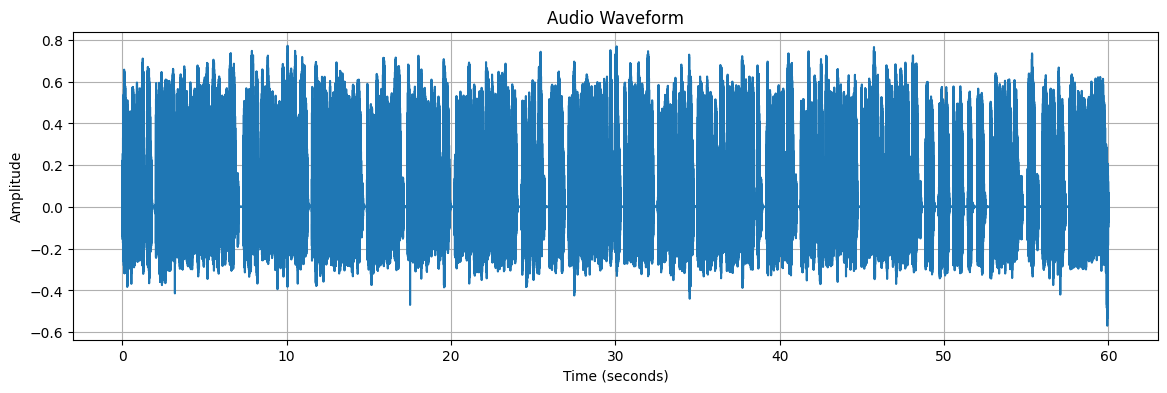

In [4]:
plt.figure(figsize=(14, 4))

plt.plot(time, audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Audio Waveform")

plt.grid()
plt.show()

In [5]:
peak_amplitude = np.max(np.abs(audio))

mean_amplitude = np.mean(audio)

mean_absolute_amplitude = np.mean(np.abs(audio))

rms = np.sqrt(np.mean(audio ** 2))

signal_energy = np.sum(audio ** 2)

print("Peak amplitude:", peak_amplitude)
print("Mean amplitude:", mean_amplitude)
print("Mean absolute amplitude:", mean_absolute_amplitude)
print("RMS:", rms)
print("Signal energy:", signal_energy)

Peak amplitude: 0.772143542766571
Mean amplitude: -0.00020321123477027255
Mean absolute amplitude: 0.10505908615794132
RMS: 0.1548551380341581
Signal energy: 31728.544158629193


In [6]:
sign_changes = np.diff(np.sign(audio))

zcr = np.count_nonzero(sign_changes) / (2 * len(audio))

print("Zero Crossing Rate:", zcr)

Zero Crossing Rate: 0.07430019522053571


In [7]:
frame_size = int(0.025 * sample_rate)  # 25 ms
hop_size = int(0.010 * sample_rate)    # 10 ms

rms_values = []

for start in range(0, len(audio) - frame_size + 1, hop_size):

    frame = audio[start:start + frame_size]

    frame_rms = np.sqrt(np.mean(frame ** 2))

    rms_values.append(frame_rms)

rms_values = np.array(rms_values)

frame_times = (
    np.arange(len(rms_values)) * hop_size
    + frame_size / 2
) / sample_rate

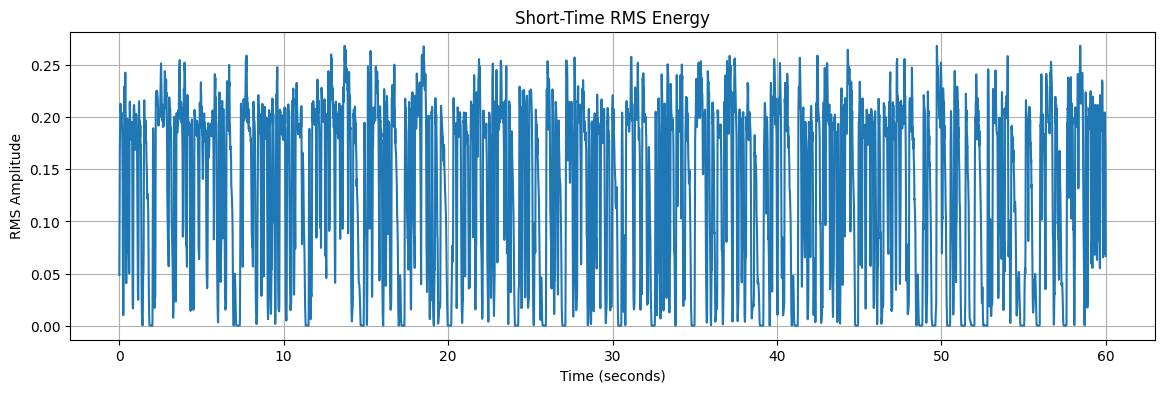

In [8]:
plt.figure(figsize=(14, 4))

plt.plot(frame_times, rms_values)

plt.xlabel("Time (seconds)")
plt.ylabel("RMS Amplitude")
plt.title("Short-Time RMS Energy")

plt.grid()
plt.show()

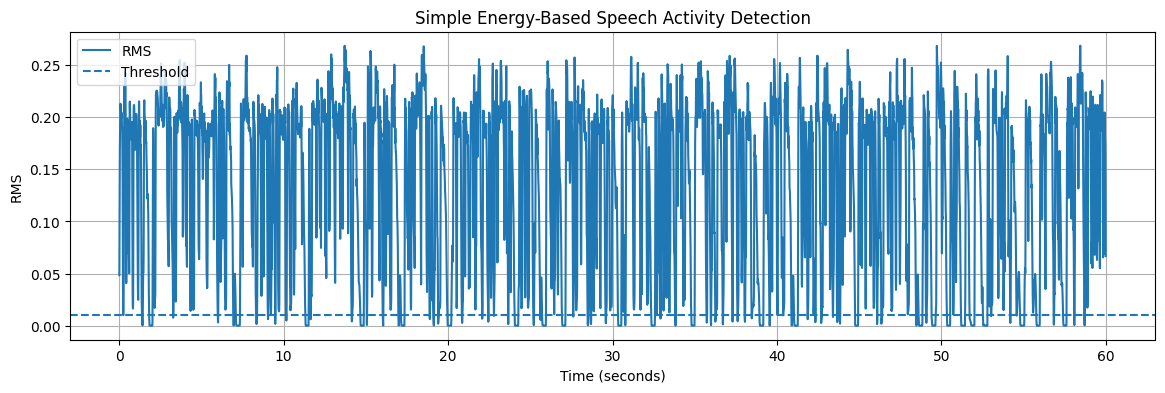

In [9]:
threshold = 0.01

is_speech = rms_values > threshold

plt.figure(figsize=(14, 4))

plt.plot(frame_times, rms_values, label="RMS")
plt.axhline(threshold, linestyle="--", label="Threshold")

plt.xlabel("Time (seconds)")
plt.ylabel("RMS")
plt.title("Simple Energy-Based Speech Activity Detection")

plt.legend()
plt.grid()
plt.show()

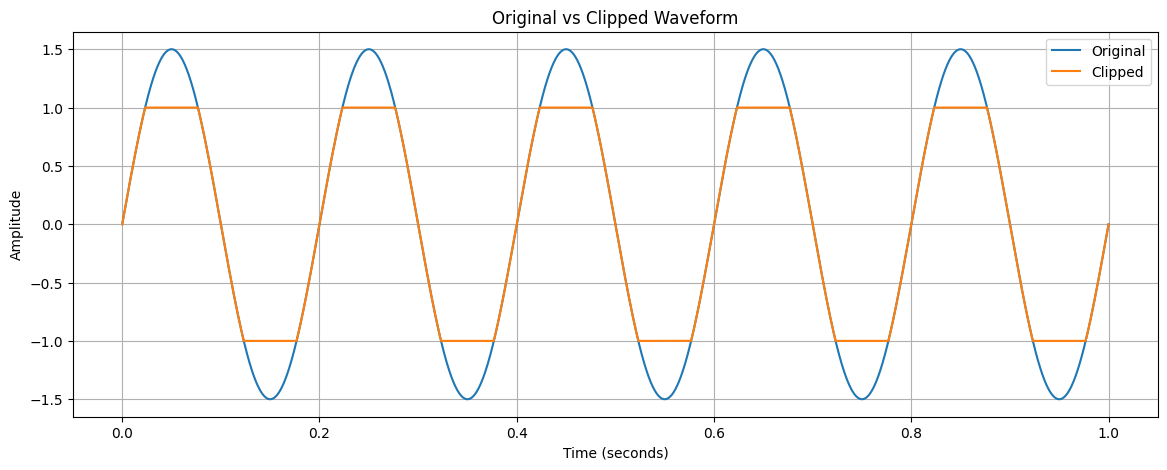

In [10]:
time_demo = np.linspace(0, 1, 2000)

original = 1.5 * np.sin(2 * np.pi * 5 * time_demo)

clipped = np.clip(original, -1, 1)

plt.figure(figsize=(14, 5))

plt.plot(time_demo, original, label="Original")
plt.plot(time_demo, clipped, label="Clipped")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Original vs Clipped Waveform")

plt.legend()
plt.grid()
plt.show()

In [11]:
audio_1, sr_1 = sf.read("audio/raw/sample-55s.mp3")
audio_2, sr_2 = sf.read("audio/raw/sample-speech-1m.mp3")

print("Speaker 1 sampling rate:", sr_1)
print("Speaker 2 sampling rate:", sr_2)

Speaker 1 sampling rate: 44100
Speaker 2 sampling rate: 22050


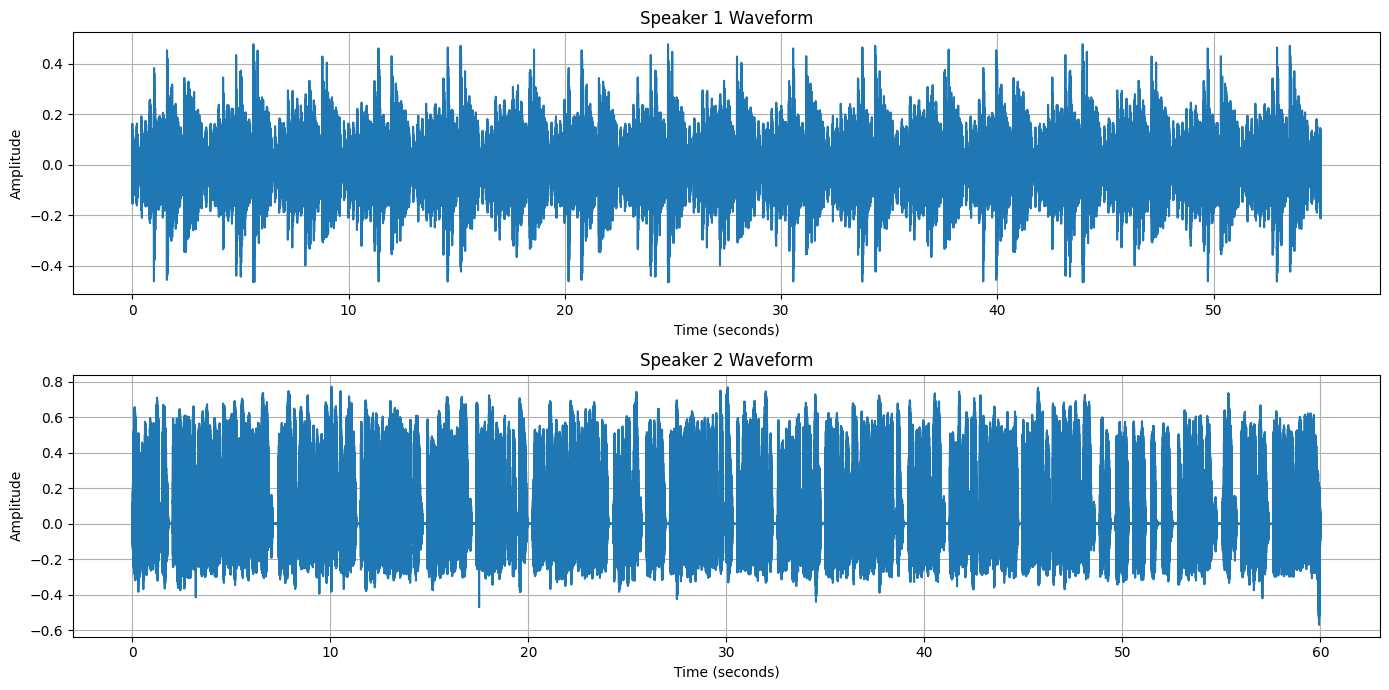

In [12]:
if audio_1.ndim == 2:
    audio_1 = audio_1.mean(axis=1)

if audio_2.ndim == 2:
    audio_2 = audio_2.mean(axis=1)

time_1 = np.arange(len(audio_1)) / sr_1
time_2 = np.arange(len(audio_2)) / sr_2

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(time_1, audio_1)
axes[0].set_title("Speaker 1 Waveform")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

axes[1].plot(time_2, audio_2)
axes[1].set_title("Speaker 2 Waveform")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()